Load your transaction dataset

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sales = pd.read_csv("../data/raw/ecommerce_sales_customer_analytics_150k.csv")

In [3]:
sales.shape

(138116, 46)

In [4]:
sales.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [5]:
sales.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'customer_postal_code', 'payment_method',
       'payment_status', 'currency', 'shipping_method', 'warehouse',
       'delivery_days', 'estimated_delivery_days', 'delivery_status',
       'return_status', 'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity',
       'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer',
       'customer_order_count'],
      dtype='str')

In [6]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country          138116 non-null  str    
 14 

Check the required columns

In [7]:
sales.columns.tolist()

['order_id',
 'order_date',
 'order_time',
 'order_status',
 'sales_channel',
 'customer_id',
 'customer_name',
 'customer_age',
 'gender',
 'customer_segment',
 'customer_type',
 'customer_city',
 'customer_state',
 'customer_country',
 'region',
 'customer_postal_code',
 'payment_method',
 'payment_status',
 'currency',
 'shipping_method',
 'warehouse',
 'delivery_days',
 'estimated_delivery_days',
 'delivery_status',
 'return_status',
 'return_reason',
 'customer_rating',
 'review_sentiment',
 'customer_review',
 'marketing_channel',
 'campaign_name',
 'coupon_code',
 'loyalty_points_earned',
 'loyalty_points_redeemed',
 'quantity',
 'gross_sales',
 'discount_amount',
 'tax_amount',
 'shipping_cost',
 'net_sales',
 'product_cost',
 'profit',
 'profit_margin_percentage',
 'customer_lifetime_value',
 'is_repeat_customer',
 'customer_order_count']

Convert Order Date

In [8]:
sales["order_date"] = pd.to_datetime(sales["order_date"])

In [9]:
sales["order_date"].dtype

dtype('<M8[us]')

In [10]:
sales["order_date"].min(), sales["order_date"].max()

(Timestamp('2021-01-01 00:00:00'), Timestamp('2025-12-31 00:00:00'))

Create customer-level features

In [11]:
customer_features = sales.groupby("customer_id").agg(
    Total_Sales=("net_sales", "sum"),
    Total_Orders=("order_id", "nunique"),
    Total_Quantity=("quantity", "sum"),
    Average_Order_Value=("net_sales", "mean"),
    Last_Purchase=("order_date", "max")
).reset_index()

In [12]:
customer_features.shape

(24911, 6)

In [13]:
customer_features.head()

,customer_id,Total_Sales,Total_Orders,Total_Quantity,Average_Order_Value,Last_Purchase
0,CUST-000001,9924.84,9,40,1102.760000,2025-12-25
1,CUST-000002,18138.96,10,54,1813.896000,2025-03-24
2,CUST-000003,7798.59,7,27,1114.084286,2025-06-05
3,CUST-000004,11218.95,7,58,1602.707143,2025-11-07
4,CUST-000005,10063.97,8,70,1257.996250,2024-11-14


Calculate Recency

In [14]:
reference_date = sales["order_date"].max()

customer_features["Recency"] = (
    reference_date -
    customer_features["Last_Purchase"]
).dt.days

In [15]:
customer_features.head()

,customer_id,Total_Sales,Total_Orders,Total_Quantity,Average_Order_Value,Last_Purchase,Recency
0,CUST-000001,9924.84,9,40,1102.760000,2025-12-25,6
1,CUST-000002,18138.96,10,54,1813.896000,2025-03-24,282
2,CUST-000003,7798.59,7,27,1114.084286,2025-06-05,209
3,CUST-000004,11218.95,7,58,1602.707143,2025-11-07,54
4,CUST-000005,10063.97,8,70,1257.996250,2024-11-14,412


Select features

In [16]:
features = [
    "Total_Sales",
    "Total_Orders",
    "Total_Quantity",
    "Average_Order_Value",
    "Recency"
]

X = customer_features[features]

In [17]:
X.shape

(24911, 5)

In [18]:
customer_features["customer_id"].nunique()

24911

Scale the Features

In [19]:
import sys

print(sys.executable)
print(sys.version)

c:\Program Files\Python312\python.exe
3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]


In [20]:
%pip install scikit-learn


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [22]:
X_scaled[:5]

array([[ 0.69133763,  1.49061705,  0.58234828, -0.31711672, -0.97324763],
       [ 2.70925397,  1.92197704,  1.50181449,  0.94764648, -0.07079213],
       [ 0.16899383,  0.62789709, -0.27144177, -0.29697635, -0.30948507],
       [ 1.0092543 ,  0.62789709,  1.76451913,  0.57204477, -0.81629884],
       [ 0.7255169 ,  1.05925707,  2.55263302, -0.04102734,  0.35427749]])

K-Means Clustering

In [23]:
from sklearn.cluster import KMeans

In [24]:
inertia = []

In [25]:
for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    model.fit(X_scaled)
    
    inertia.append(model.inertia_)

In [26]:
print(inertia)

[77832.27608061723, 63092.25204298221, 52584.59010674605, 44201.269102729195, 40528.58785809465, 37359.76292573389, 34593.81489494961, 32039.57955914081, 30248.569522694444]


In [27]:
import matplotlib.pyplot as plt

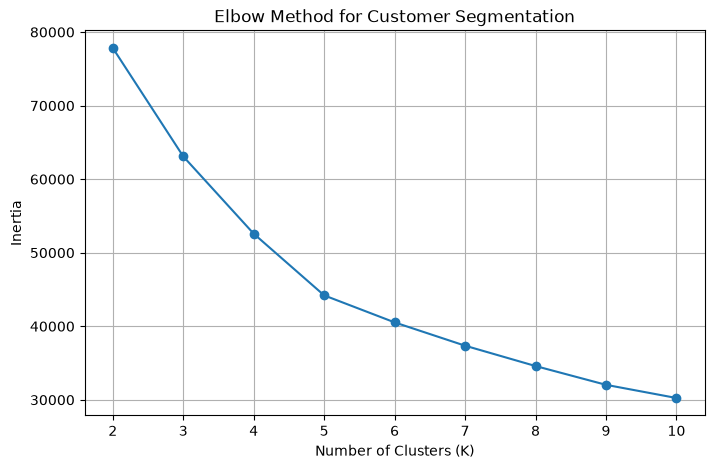

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [29]:
optimal_k = 5

In [30]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

In [31]:
kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 5)","[[ 1.

In [32]:
customer_features["Cluster"] = kmeans.labels_

In [33]:
customer_features.head()

,customer_id,Total_Sales,Total_Orders,Total_Quantity,Average_Order_Value,Last_Purchase,Recency,Cluster
0,CUST-000001,9924.84,9,40,1102.760000,2025-12-25,6,4
1,CUST-000002,18138.96,10,54,1813.896000,2025-03-24,282,0
2,CUST-000003,7798.59,7,27,1114.084286,2025-06-05,209,4
3,CUST-000004,11218.95,7,58,1602.707143,2025-11-07,54,0
4,CUST-000005,10063.97,8,70,1257.996250,2024-11-14,412,0


Interpret Your 5 Clusters

In [34]:
cluster_profile = customer_features.groupby("Cluster")[features].mean()

cluster_profile

,Total_Sales,Total_Orders,Total_Quantity,Average_Order_Value,Recency
Cluster,,,,,
0,13665.104097,8.921360,55.597503,1568.954953,154.851222
1,3419.356066,3.127530,16.214912,1109.690643,918.912955
2,3617.459793,3.999002,19.043323,925.264643,229.958387
3,9243.609635,4.506586,30.135565,2113.396751,326.850988
4,7510.823140,6.751263,36.530710,1133.226711,193.174289


In [35]:
cluster_sizes = customer_features["Cluster"].value_counts().sort_index()

cluster_sizes

Cluster
0    3764
1    2964
2    7017
3    3644
4    7522
Name: count, dtype: int64

In [36]:
cluster_percentage = (
    customer_features["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

cluster_percentage

Cluster
0    15.109791
1    11.898358
2    28.168279
3    14.628076
4    30.195496
Name: proportion, dtype: float64

Compare Multiple Clustering Algorithms

In [37]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

customer_features["KMeans_Cluster"] = kmeans_labels

In [38]:
customer_features["KMeans_Cluster"].value_counts().sort_index()

KMeans_Cluster
0    3764
1    2964
2    7017
3    3644
4    7522
Name: count, dtype: int64

In [39]:
from sklearn.cluster import AgglomerativeClustering

In [40]:
agglo = AgglomerativeClustering(
    n_clusters=5
)

agglo_labels = agglo.fit_predict(X_scaled)

In [41]:
customer_features["Agglomerative_Cluster"] = agglo_labels

In [42]:
customer_features["Agglomerative_Cluster"].value_counts().sort_index()

Agglomerative_Cluster
0    7825
1    7135
2    2706
3    5619
4    1626
Name: count, dtype: int64

In [43]:
from sklearn.cluster import DBSCAN

In [44]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

In [45]:
customer_features["DBSCAN_Cluster"] = dbscan_labels

In [46]:
customer_features["DBSCAN_Cluster"].value_counts().sort_index()

DBSCAN_Cluster
-1       513
 0     24302
 1         3
 2        23
 3         4
 4         7
 5         5
 6        16
 7         7
 8         7
 9         5
 10        5
 11        3
 12        6
 13        5
Name: count, dtype: int64

Evaluate the Clustering

In [47]:
from sklearn.metrics import silhouette_score

In [48]:
kmeans_score = silhouette_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Silhouette Score:", kmeans_score)

K-Means Silhouette Score: 0.26390310028723035


In [49]:
agglo_score = silhouette_score(
    X_scaled,
    agglo_labels
)

print("Agglomerative Silhouette Score:", agglo_score)

Agglomerative Silhouette Score: 0.1724472839386068


In [50]:
import numpy as np

dbscan_mask = dbscan_labels != -1

In [51]:
print("Total customers:", len(dbscan_labels))
print("Non-noise customers:", dbscan_mask.sum())
print("Noise customers:", (~dbscan_mask).sum())

Total customers: 24911
Non-noise customers: 24398
Noise customers: 513


In [52]:
dbscan_score = silhouette_score(
    X_scaled[dbscan_mask],
    dbscan_labels[dbscan_mask]
)

print("DBSCAN Silhouette Score:", dbscan_score)

DBSCAN Silhouette Score: 0.10143642659196929


In [53]:
results = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Agglomerative",
        "DBSCAN"
    ],
    "Silhouette Score": [
        kmeans_score,
        agglo_score,
        dbscan_score
    ]
})

results

,Algorithm,Silhouette Score
0,K-Means,0.263903
1,Agglomerative,0.172447
2,DBSCAN,0.101436


In [54]:
customer_features.to_csv(
    "../data/ml/customer_segmentation_results.csv",
    index=False
)

In [55]:
import joblib

joblib.dump(
    scaler,
    "../models/customer_segmentation_scaler.pkl"
)

['../models/customer_segmentation_scaler.pkl']

In [56]:
joblib.dump(
    kmeans,
    "../models/customer_segmentation_kmeans.pkl"
)

['../models/customer_segmentation_kmeans.pkl']

In [57]:
results.to_csv(
    "../results/clustering_comparison.csv",
    index=False
)